In [7]:
import torch
import platform

print("Python Version:", platform.python_version())
print("PyTorch Version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU Available: Yes")
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
else:
    print("GPU Available: No")

!nvidia-smi


Python Version: 3.13.18
PyTorch Version: 2.14.1+cpu
GPU Available: No
/bin/bash: line 1: nvidia-smi: command not found


In [8]:
!pip install -q ultralytics pandas matplotlib

In [9]:
from ultralytics import YOLO

# Load pretrained object detection model
model = YOLO("yolov8n.pt")

print("YOLO Model Loaded Successfully!")
print("Model Task:", model.task)


YOLO Model Loaded Successfully!
Model Task: detect


In [10]:
from ultralytics.utils.downloads import download
import os

# Download COCO8 sample dataset
download(
    "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco8.zip",
    dir="/content/datasets",
    unzip=True
)

dataset_path = "/content/datasets/coco8"

print("Dataset Downloaded Successfully!")
print("Dataset Path:", dataset_path)


WARNING ⚠️ Skipping /content/datasets/coco8.zip unzip as destination path /content/datasets/coco8 already exists.
Dataset Downloaded Successfully!
Dataset Path: /content/datasets/coco8


In [11]:
# Validate the model on COCO8

metrics = model.val(
    data="coco8.yaml",
    imgsz=640,
    batch=4,
    device=0 if torch.cuda.is_available() else "cpu"
)

print("\n--- Detection Evaluation Results ---")

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.220 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD EPYC 7B12)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2753.6±719.9 MB/s, size: 54.0 KB)
val: Scanning /content/datasets/coco8/labels/val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 1.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.3it/s 0.8s
                   all          4         17      0.621      0.833      0.902      0.636
                person          3         10      0.721        0.5      0.575       0.28
                   dog          1          1       0.37          1          1        0.6
                 horse          1          2      0.751          1          1      0.636
              elephant          1          2      0.505        0.5      0.835      0.397
              umbrella          1          1      0.564     

In [12]:
import time
import numpy as np

device = 0 if torch.cuda.is_available() else "cpu"

# Sample input images from dataset
image_folder = "/content/datasets/coco8/images/val"

import glob

images = glob.glob(image_folder + "/*.jpg")

print("Number of test images:", len(images))

# Warm-up
for _ in range(5):
    model.predict(images[0], imgsz=640, device=device, verbose=False)

if torch.cuda.is_available():
    torch.cuda.synchronize()

# Measure inference time
start = time.perf_counter()

num_runs = 30

for i in range(num_runs):
    model.predict(
        images[i % len(images)],
        imgsz=640,
        device=device,
        verbose=False
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

end = time.perf_counter()

total_time = end - start

latency = (total_time / num_runs) * 1000
throughput = num_runs / total_time

print("Average Latency:", round(latency, 3), "ms")
print("Throughput:", round(throughput, 2), "images/sec")


Number of test images: 4
Average Latency: 119.886 ms
Throughput: 8.34 images/sec


In [13]:
if torch.cuda.is_available():

    torch.cuda.reset_peak_memory_stats()

    sample_image = images[0]

    model.predict(
        sample_image,
        imgsz=640,
        device=0,
        verbose=False
    )

    torch.cuda.synchronize()

    allocated = torch.cuda.memory_allocated() / (1024 ** 2)
    reserved = torch.cuda.memory_reserved() / (1024 ** 2)
    peak = torch.cuda.max_memory_allocated() / (1024 ** 2)

    print("GPU Memory Allocated:", round(allocated, 2), "MB")
    print("GPU Memory Reserved:", round(reserved, 2), "MB")
    print("Peak GPU Memory:", round(peak, 2), "MB")

else:
    print("GPU memory measurement requires CUDA.")


GPU memory measurement requires CUDA.


In [14]:
import pandas as pd

results = {
    "Metric": [
        "Precision",
        "Recall",
        "mAP50",
        "mAP50-95",
        "Latency (ms)",
        "Throughput (images/sec)"
    ],
    "Measured Value": [
        metrics.box.mp,
        metrics.box.mr,
        metrics.box.map50,
        metrics.box.map,
        latency,
        throughput
    ]
}

if torch.cuda.is_available():
    results["Metric"].append("Peak GPU Memory (MB)")
    results["Measured Value"].append(peak)

report = pd.DataFrame(results)

print("INFERENCE BASELINE REPORT")
display(report)

report.to_csv(
    "/content/inference_baseline_report.csv",
    index=False
)

print("Report saved successfully!")


INFERENCE BASELINE REPORT


,Metric,Measured Value
0,Precision,0.620971
1,Recall,0.833333
2,mAP50,0.901693
3,mAP50-95,0.635580
4,Latency (ms),119.885756
5,Throughput (images/sec),8.341275


Report saved successfully!


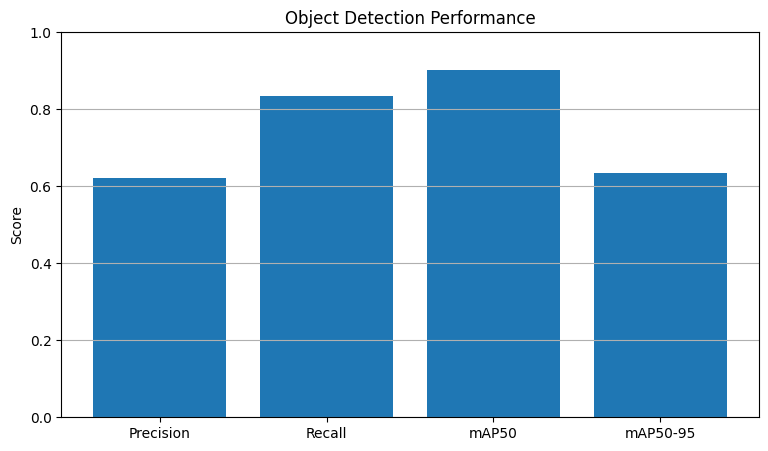

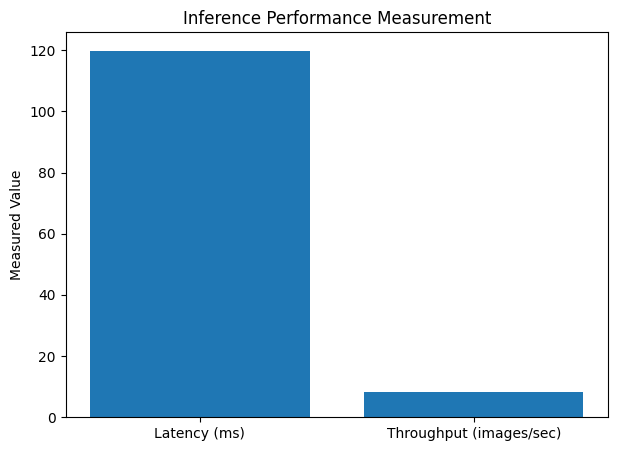

In [15]:
import matplotlib.pyplot as plt

# Detection quality metrics
quality_metrics = {
    "Precision": metrics.box.mp,
    "Recall": metrics.box.mr,
    "mAP50": metrics.box.map50,
    "mAP50-95": metrics.box.map
}

plt.figure(figsize=(9, 5))
plt.bar(quality_metrics.keys(), quality_metrics.values())
plt.title("Object Detection Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()

# Performance metrics
plt.figure(figsize=(7, 5))
plt.bar(["Latency (ms)", "Throughput (images/sec)"],
        [latency, throughput])
plt.title("Inference Performance Measurement")
plt.ylabel("Measured Value")
plt.show()
